# Predicting Loan Default
**CECS 456 Final Project · Phu Quach, Om Patel and David Ramos · Fall 2026**

This notebook follows the plan in our proposal:

1. Load the data 
2. Exploratory Data Analysis
3. Clean the data
4. Split into training and test sets
5. Set up preprocessing
6. Tune the models
7. Compare the models with cross-validation
8. Ablations (remove some features and retrain)
9. Final test results
10. What the model learned
11. Errors by age group and by renters vs. non-renters
12. Predict a new application
13. Summary and limitations

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_validate
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, roc_auc_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.base import clone
from scipy.stats import loguniform, randint

## 1. Load the data

We taking the dataset from *Loan Approval Prediction Dataset-2.zip* on Canvas. 

In [2]:
df = pd.read_csv("credit_risk_dataset 2.csv")
print(df.shape)
df.head(10)

(32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
5,21,9900,OWN,2.0,VENTURE,A,2500,7.14,1,0.25,N,2
6,26,77100,RENT,8.0,EDUCATION,B,35000,12.42,1,0.45,N,3
7,24,78956,RENT,5.0,MEDICAL,B,35000,11.11,1,0.44,N,4
8,24,83000,RENT,8.0,PERSONAL,A,35000,8.90,1,0.42,N,2
9,21,10000,OWN,6.0,VENTURE,D,1600,14.74,1,0.16,N,3


In [3]:
df.dtypes

person_age                      int64
person_income                   int64
person_home_ownership          object
person_emp_length             float64
loan_intent                    object
loan_grade                     object
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file      object
cb_person_cred_hist_length      int64
dtype: object

In [4]:
num_cols = ["person_age", "person_income", "person_emp_length", "loan_amnt",
            "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length"]
cat_cols = ["person_home_ownership", "loan_intent", "loan_grade", "cb_person_default_on_file"]

print(len(num_cols), "numeric features")
print(len(cat_cols), "categorical features")
print("target: loan_status")

7 numeric features
4 categorical features
target: loan_status


In [5]:
grade_table = df.groupby("loan_grade")["loan_status"].agg(["count", "mean"])
grade_table["mean"] = (grade_table["mean"] * 100).round(1)
grade_table.columns = ["loans", "% with loan_status = 1"]
grade_table

,loans,% with loan_status = 1
loan_grade,,
A,10777,10.0
B,10451,16.3
C,6458,20.7
D,3626,59.0
E,964,64.4
F,241,70.5
G,64,98.4


## 2. Explore the data

### a. Class balance

loan_status
0    25473
1     7108
Name: count, dtype: int64

loan_status
0    78.2
1    21.8
Name: count, dtype: float64


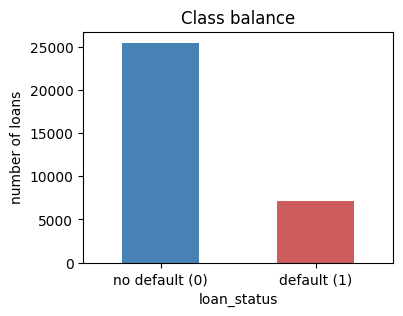

In [6]:
counts = df["loan_status"].value_counts()
print(counts)
print()
print((counts / len(df) * 100).round(1))

counts.plot.bar(color=["steelblue", "indianred"], figsize=(4, 3))
plt.xticks([0, 1], ["no default (0)", "default (1)"], rotation=0)
plt.ylabel("number of loans")
plt.title("Class balance")
plt.show()

Accoding to our investigation, about 78% of loans are 0 (no default) and 22% are 1 (default). Because of this imbalance, accuracy is misleading: a model that always says "no default" would already be 78% accurate.

### b. Missing values

In [7]:
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(1)
pd.DataFrame({"missing": missing, "percent": missing_pct})[missing > 0]

,missing,percent
person_emp_length,895,2.7
loan_int_rate,3116,9.6


Interest rate is missing for about 10% of loans and employment length for about 3%. We will fill them with the median from the training data and add a column that marks which values were missing.

### c. Overall and Checking Outliers

In [8]:
display(df.describe().round(2))

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.00,32581.00,31686.00,32581.00,29465.00,32581.00,32581.00,32581.00
mean,27.73,66074.85,4.79,9589.37,11.01,0.22,0.17,5.80
std,6.35,61983.12,4.14,6322.09,3.24,0.41,0.11,4.06
min,20.00,4000.00,0.00,500.00,5.42,0.00,0.00,2.00
25%,23.00,38500.00,2.00,5000.00,7.90,0.00,0.09,3.00
50%,26.00,55000.00,4.00,8000.00,10.99,0.00,0.15,4.00
75%,30.00,79200.00,7.00,12200.00,13.47,0.00,0.23,8.00
max,144.00,6000000.00,123.00,35000.00,23.22,1.00,0.83,30.00


In [9]:
print("duplicate rows:", df.duplicated().sum())
print("ages over 100:", sorted(df.loc[df["person_age"] > 100, "person_age"]))
print("employment length:", sorted(df.loc[df["person_emp_length"] > 60, "person_emp_length"]))
print("median income:", df["person_income"].median())
print("max income:", df["person_income"].max())

duplicate rows: 165
ages over 100: [123, 123, 144, 144, 144]
employment length: [123.0, 123.0]
median income: 55000.0
max income: 6000000


We find out that some values are impossible such as ages of 123 and 144, and 123 years of employment. We will remove those rows. Income is very skewed (median $55,000, max $6 million), so we will use the log of income instead.

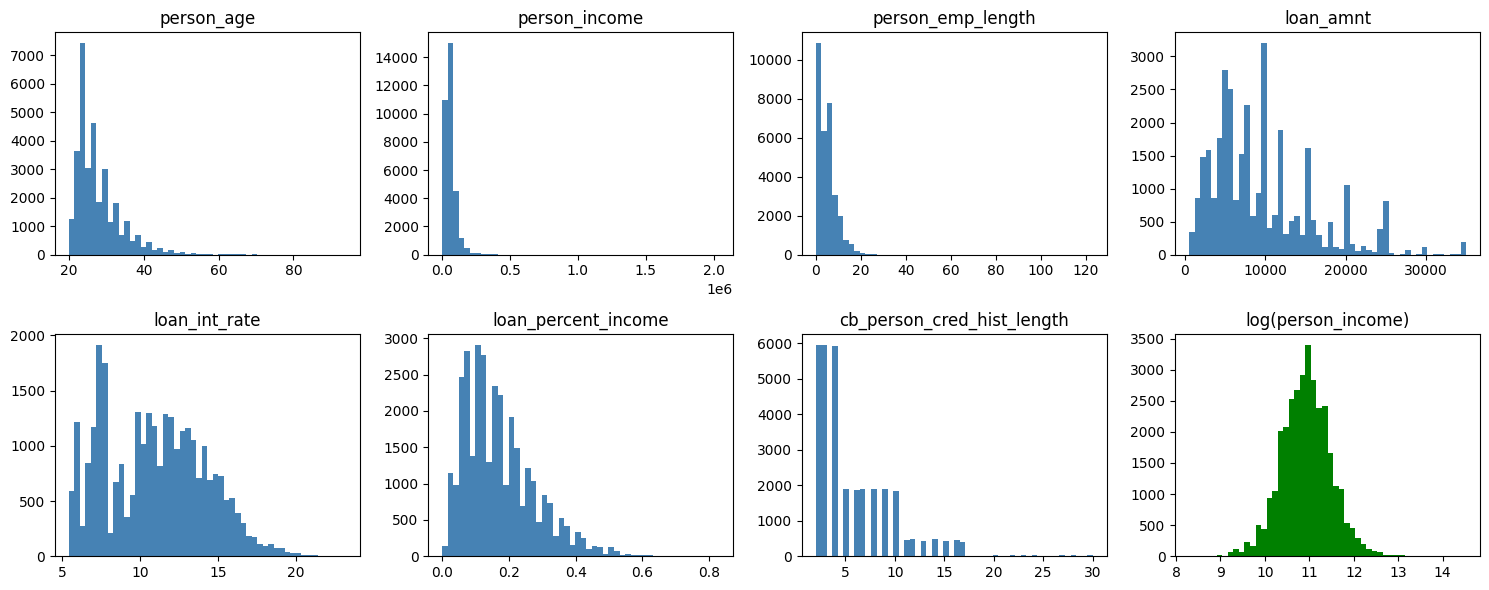

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
no_outliers = df[df["person_age"] <= 100]

for ax, col in zip(axes.flat, num_cols):
    ax.hist(no_outliers[col].dropna(), bins=50, color="steelblue")
    ax.set_title(col)

axes.flat[7].hist(np.log(no_outliers["person_income"]), bins=50, color="green")
axes.flat[7].set_title("log(person_income)")
plt.tight_layout()
plt.show()

### Default rate by group

Default rates change a lot with home ownership, loan purpose, and past defaults, so these columns should help the models.

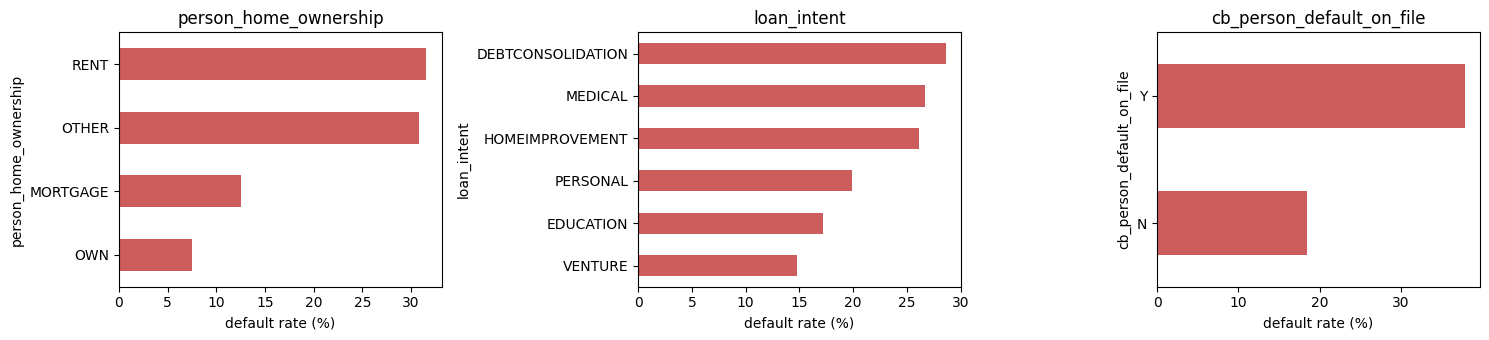

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col in zip(axes, ["person_home_ownership", "loan_intent", "cb_person_default_on_file"]):
    rate = df.groupby(col)["loan_status"].mean().sort_values() * 100
    rate.plot.barh(ax=ax, color="indianred")
    ax.set_xlabel("default rate (%)")
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 3. Clean the data

We clean the data before splitting it, so that a duplicate loan cannot end up in both the training set and the test set.

1. Remove duplicate rows
2. Remove impossible ages
3. Remove impossible employment lengths : 2 applicants aged 21 and 22 are listed with 123 years of work experience. We remove any row where the years worked is more than the person's age minus 14
4. Use log(income) instead of income: Income is very skewed: most people earn around $55,000, but a few earn up to $6 million. Taking the log pulls these extreme values closer to the rest, which helps the models that measure distances or fit weights (logistic regression, Naive Bayes, k-NN, SVM, MLP). Tree models are not affected, because the log keeps incomes in the same order.

Using the log before the split is safe. It is a simple math formula applied to each row on its own, so nothing is learned from the other rows or from the test set.

In [12]:
data = df.drop_duplicates()
data = data[data["person_age"] <= 100]
data = data[~(data["person_emp_length"] > data["person_age"] - 14)]   # rows with missing employment length are kept

data["log_income"] = np.log(data["person_income"])
data = data.drop(columns="person_income")
num_cols = ["log_income" if c == "person_income" else c for c in num_cols]

print("rows before:", len(df))
print("rows after: ", len(data))
print("default rate after cleaning:", round(data["loan_status"].mean() * 100, 1), "%")

rows before: 32581
rows after:  32409
default rate after cleaning: 21.9 %


## 4. Split into training and test sets

We keep 80% of the loans for training and set aside 20% as a test set. stratify=y makes sure both parts have the same share of defaults.

In [13]:
X = data.drop(columns="loan_status")
y = data["loan_status"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("training set:", len(X_train), "loans,", round(y_train.mean() * 100, 1), "% default")
print("test set:    ", len(X_test), "loans,", round(y_test.mean() * 100, 1), "% default")

training set: 25927 loans, 21.9 % default
test set:     6482 loans, 21.9 % default


## 5. Set up preprocessing

The data analysis part is complete above. In this part, we prepare the features and train the models. Imputation, scaling, and one-hot encoding are inside the pipeline. This means each training fold learns its own preprocessing values, and information from the test set is not used.

In [14]:
# Separate the numeric and categorical columns
numeric_features = [column for column in num_cols if column in X_train.columns]
categorical_features = [column for column in cat_cols if column in X_train.columns]

# Fill missing numbers with the median and mark which values were missing
numeric_preprocessing = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler())
])

# Fill missing categories and turn categories into numbers
categorical_preprocessing = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ("numbers", numeric_preprocessing, numeric_features),
    ("categories", categorical_preprocessing, categorical_features)
])

print("numeric columns:", numeric_features)
print("categorical columns:", categorical_features)

numeric columns: ['person_age', 'log_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
categorical columns: ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']


## 6. Tune the models

We use five-fold stratified cross-validation. Each fold keeps about the same share of defaults. PR-AUC is the main score because the default class is smaller. The randomized search tries a small set of settings for each model. k-NN and SVM are tuned on a random 30% sample of the training set because they take longer to run.

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# This function makes the same preprocessing pipeline for each model

def make_model_pipeline(model):
    return Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("model", model)
    ])

# The majority baseline always predicts the most common class
majority_model = DummyClassifier(strategy="most_frequent")
majority_scores = cross_validate(
    majority_model, X_train, y_train, cv=cv,
    scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc",
             "accuracy": "accuracy", "precision": "precision",
             "recall": "recall", "f1": "f1"},
    n_jobs=-1
)

print("Majority baseline average PR-AUC:", round(majority_scores["test_pr_auc"].mean(), 3))
print("Majority baseline average accuracy:", round(majority_scores["test_accuracy"].mean(), 3))

Majority baseline average PR-AUC: 0.219
Majority baseline average accuracy: 0.781


### Search settings

We use the same five folds and score every search with PR-AUC. The best settings are chosen using training data only.

In [16]:
model_options = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42),
        {"model__C": loguniform(0.01, 10)}
    ),
    "Decision Tree": (
        DecisionTreeClassifier(class_weight="balanced", random_state=42),
        {"model__max_depth": [3, 5, 8, 12, None],
         "model__min_samples_leaf": randint(5, 50)}
    ),
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1),
        {"model__n_estimators": randint(100, 251),
         "model__max_depth": [None, 8, 12, 18],
         "model__min_samples_leaf": randint(2, 15)}
    ),
    "Gradient Boosting": (
        HistGradientBoostingClassifier(random_state=42),
        {"model__learning_rate": loguniform(0.03, 0.2),
         "model__max_iter": randint(100, 251),
         "model__max_leaf_nodes": randint(7, 32),
         "model__l2_regularization": loguniform(0.001, 10)}
    ),
    "k-NN": (
        KNeighborsClassifier(),
        {"model__n_neighbors": randint(5, 41),
         "model__weights": ["uniform", "distance"],
         "model__p": [1, 2]}
    ),
    "RBF SVM": (
        SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=42),
        {"model__C": loguniform(0.1, 10),
         "model__gamma": ["scale", "auto"]}
    )
}

# Use 30% of training data for k-NN and SVM searches
X_tune, _, y_tune, _ = train_test_split(
    X_train, y_train, train_size=0.30, stratify=y_train, random_state=42
)

best_models = {}
search_rows = []

for name, (classifier, parameters) in model_options.items():
    if name in ["k-NN", "RBF SVM"]:
        search_X, search_y = X_tune, y_tune
    else:
        search_X, search_y = X_train, y_train

    search = RandomizedSearchCV(
        estimator=make_model_pipeline(classifier),
        param_distributions=parameters,
        n_iter=5,
        scoring="average_precision",
        cv=cv,
        random_state=42,
        n_jobs=-1,
        refit=True
    )
    search.fit(search_X, search_y)

    # Refit the chosen settings on all training data
    best_models[name] = search.best_estimator_
    best_models[name].fit(X_train, y_train)
    search_rows.append({
        "model": name,
        "best CV PR-AUC": search.best_score_,
        "best settings": search.best_params_,
        "search data": "30% sample" if name in ["k-NN", "RBF SVM"] else "all training data"
    })
    print(name, "finished. Best CV PR-AUC:", round(search.best_score_, 3))

search_results = pd.DataFrame(search_rows).sort_values("best CV PR-AUC", ascending=False)
search_results

Logistic Regression finished. Best CV PR-AUC: 0.725
Decision Tree finished. Best CV PR-AUC: 0.854
Random Forest finished. Best CV PR-AUC: 0.875
Gradient Boosting finished. Best CV PR-AUC: 0.9
k-NN finished. Best CV PR-AUC: 0.771
RBF SVM finished. Best CV PR-AUC: 0.814


,model,best CV PR-AUC,best settings,search data
3,Gradient Boosting,0.900268,{'model__l2_regularization': 2.915443189153754...,all training data
2,Random Forest,0.874817,"{'model__max_depth': None, 'model__min_samples...",all training data
1,Decision Tree,0.854111,"{'model__max_depth': 12, 'model__min_samples_l...",all training data
5,RBF SVM,0.813609,"{'model__C': 1.5751320499779735, 'model__gamma...",30% sample
4,k-NN,0.771171,"{'model__n_neighbors': 40, 'model__p': 2, 'mod...",30% sample
0,Logistic Regression,0.725098,{'model__C': 7.114476009343421},all training data


## 7. Compare models with cross-validation

For most models, the search cross-validation used all of the training set. For k-NN and SVM, the search used the planned 30% training sample to save time. After selecting settings, every model is refit using all of the training set. The test set remains untouched until the final results.

In [17]:
# Compare the best settings. The CV score for k-NN and SVM comes from their 30% search sample.
comparison = search_results[["model", "best CV PR-AUC", "search data"]].copy()
comparison = comparison.rename(columns={"best CV PR-AUC": "PR-AUC"})
comparison = pd.concat([
    comparison,
    pd.DataFrame([{
        "model": "Majority baseline",
        "PR-AUC": majority_scores["test_pr_auc"].mean(),
        "search data": "all training data"
    }])
], ignore_index=True)
comparison.sort_values("PR-AUC", ascending=False).reset_index(drop=True)

,model,PR-AUC,search data
0,Gradient Boosting,0.900268,all training data
1,Random Forest,0.874817,all training data
2,Decision Tree,0.854111,all training data
3,RBF SVM,0.813609,30% sample
4,k-NN,0.771171,30% sample
5,Logistic Regression,0.725098,all training data
6,Majority baseline,0.218691,all training data


## 8. Ablations: remove selected features

The proposal asks us to check whether the model still works without loan grade and interest rate, and then without age. We use the model with the highest training cross-validation PR-AUC for these comparisons. Each version is trained using only the training set.

In [18]:
best_name = search_results.iloc[0]["model"]
print("Selected model:", best_name)

# Build a preprocessing pipeline using only the columns kept in each version

def make_preprocessor(columns):
    numbers = [column for column in numeric_features if column in columns]
    categories = [column for column in categorical_features if column in columns]

    number_steps = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler())
    ])
    category_steps = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])
    return ColumnTransformer(transformers=[
        ("numbers", number_steps, numbers),
        ("categories", category_steps, categories)
    ])

full_columns = list(X_train.columns)
without_grade_rate = [column for column in full_columns
                      if column not in ["loan_grade", "loan_int_rate"]]
without_grade_rate_age = [column for column in without_grade_rate
                          if column != "person_age"]

feature_versions = {
    "All features": full_columns,
    "Without loan grade and interest rate": without_grade_rate,
    "Without loan grade, interest rate, and age": without_grade_rate_age
}

ablation_models = {}
ablation_rows = []

for version, columns in feature_versions.items():
    pipeline = Pipeline(steps=[
        ("preprocessing", make_preprocessor(columns)),
        ("model", clone(best_models[best_name].named_steps["model"]))
    ])
    pipeline.fit(X_train[columns], y_train)
    ablation_models[version] = pipeline
    ablation_rows.append({
        "features": version,
        "training columns": len(columns),
        "test PR-AUC": average_precision_score(
            y_test, pipeline.predict_proba(X_test[columns])[:, 1]
        )
    })

pd.DataFrame(ablation_rows)

Selected model: Gradient Boosting


,features,training columns,test PR-AUC
0,All features,11,0.908750
1,Without loan grade and interest rate,9,0.823824
2,"Without loan grade, interest rate, and age",8,0.819758


## 9. Final test results

We now use the held-out test set once to compare the seven approaches. The table includes PR-AUC, ROC-AUC, accuracy, precision, recall, and F1. Recall tells us how many actual defaults were flagged. Precision tells us how often a default warning was correct.

In [19]:
final_models = {"Majority baseline": majority_model}
final_models.update(best_models)

final_rows = []
for name, model in final_models.items():
    if name == "Majority baseline":
        predictions = model.fit(X_train, y_train).predict(X_test)
        probabilities = np.zeros(len(y_test))  # baseline has no default-risk score
    else:
        predictions = model.predict(X_test)
        probabilities = model.predict_proba(X_test)[:, 1]

    final_rows.append({
        "model": name,
        "PR-AUC": average_precision_score(y_test, probabilities),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(y_test, predictions, zero_division=0),
        "recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0)
    })

final_results = pd.DataFrame(final_rows).sort_values("PR-AUC", ascending=False)
final_results

,model,PR-AUC,ROC-AUC,accuracy,precision,recall,F1
4,Gradient Boosting,0.908750,0.950509,0.939525,0.976766,0.741185,0.842823
3,Random Forest,0.883370,0.932053,0.917618,0.851351,0.755289,0.800448
2,Decision Tree,0.865581,0.919584,0.889540,0.733068,0.778561,0.755130
6,RBF SVM,0.848532,0.915106,0.881827,0.710052,0.777151,0.742088
5,k-NN,0.816375,0.899780,0.892934,0.900442,0.574048,0.701120
1,Logistic Regression,0.712101,0.876325,0.807004,0.540010,0.794781,0.643081
0,Majority baseline,0.218760,0.500000,0.781240,0.000000,0.000000,0.000000


## 10. Confusion matrices and curves

A confusion matrix shows correct and incorrect predictions. The curves show how performance changes when we change the threshold used to flag a loan as a possible default.

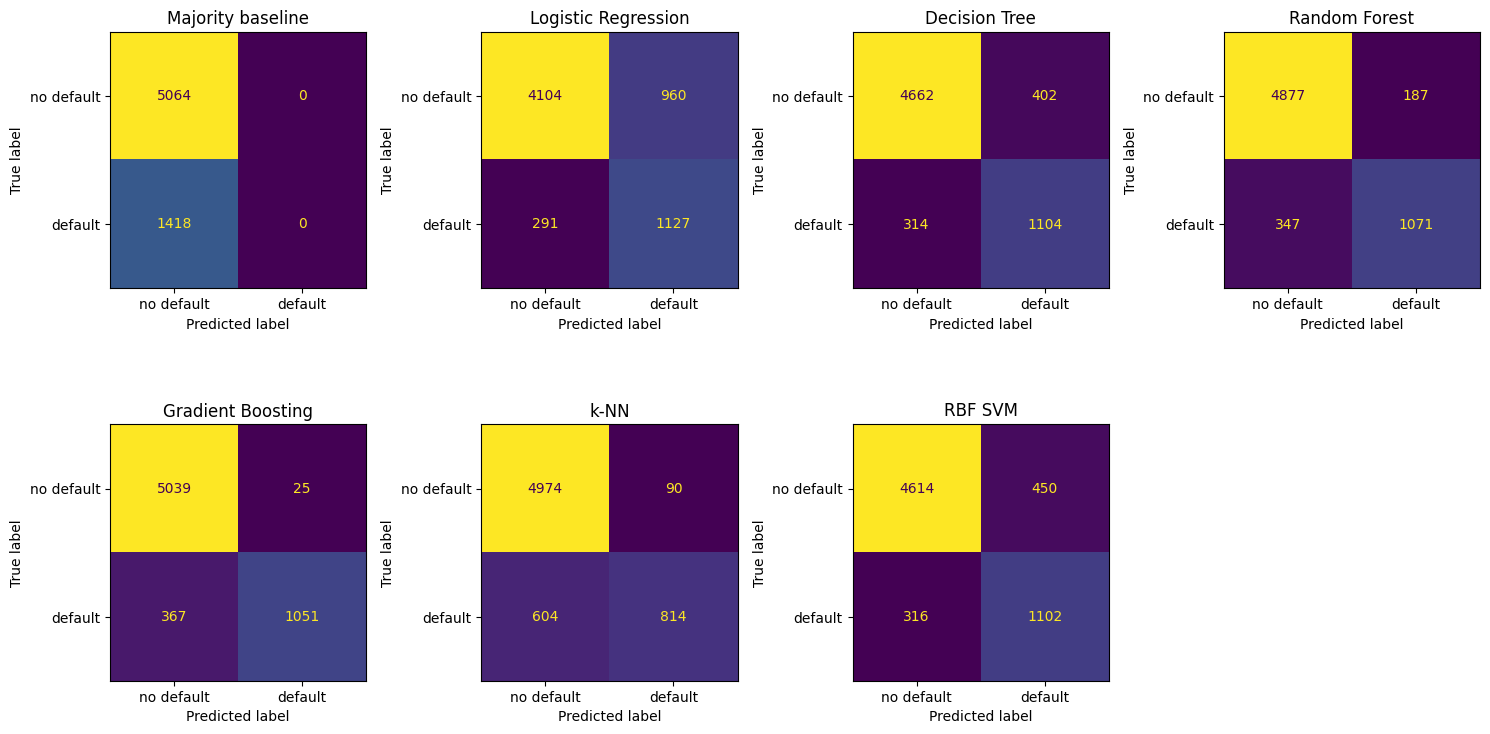

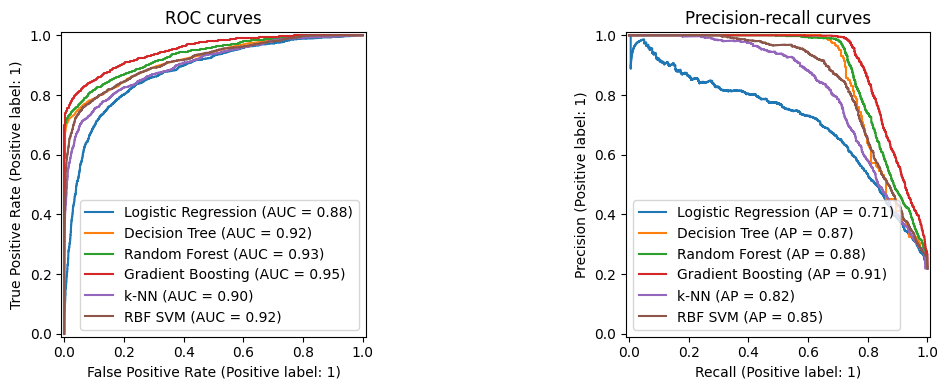

In [20]:
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
axes = axes.flatten()

for ax, (name, model) in zip(axes, final_models.items()):
    predictions = model.predict(X_test) if name != "Majority baseline" else model.predict(X_test)
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, display_labels=["no default", "default"],
        colorbar=False, ax=ax
    )
    ax.set_title(name)

axes[-1].axis("off")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, model in best_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_estimator(model, X_test, y_test, name=name, ax=axes[1])
axes[0].set_title("ROC curves")
axes[1].set_title("Precision-recall curves")
plt.tight_layout()
plt.show()

## 11. What the model learned

Permutation importance measures how much the model's PR-AUC drops when one feature is shuffled. A larger drop means the model relied more on that feature for these predictions. This describes patterns in this dataset; it does not show that a feature causes default.

In [21]:
selected_model = best_models[best_name]
importance = permutation_importance(
    selected_model, X_test, y_test,
    scoring="average_precision", n_repeats=3, random_state=42, n_jobs=-1
)
importance_table = pd.DataFrame({
    "feature": X_test.columns,
    "importance": importance.importances_mean
}).sort_values("importance", ascending=False)
importance_table.head(10)

,feature,importance
7,loan_percent_income,0.267582
1,person_home_ownership,0.184667
10,log_income,0.158627
3,loan_intent,0.126761
4,loan_grade,0.087773
6,loan_int_rate,0.056510
0,person_age,0.025292
2,person_emp_length,0.023262
5,loan_amnt,0.003499
9,cb_person_cred_hist_length,0.000174


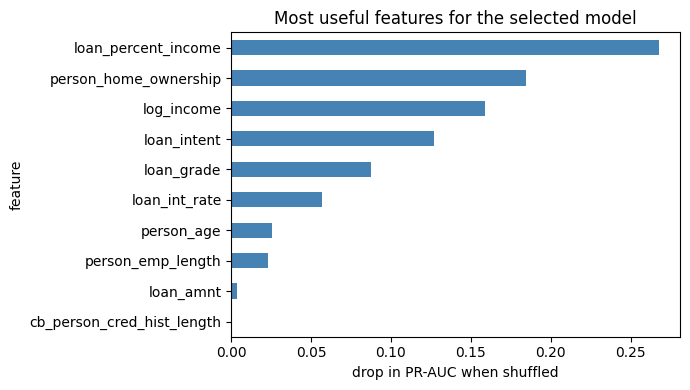

In [22]:
importance_table.head(10).sort_values("importance").plot.barh(
    x="feature", y="importance", legend=False, color="steelblue", figsize=(7, 4)
)
plt.xlabel("drop in PR-AUC when shuffled")
plt.title("Most useful features for the selected model")
plt.tight_layout()
plt.show()

### Decision tree rules

The single decision tree is the easiest model here to explain as a set of if-then rules. These rules are approximate patterns learned from the training data.

In [23]:
tree_model = best_models["Decision Tree"]
feature_names = tree_model.named_steps["preprocessing"].get_feature_names_out()
rules = export_text(
    tree_model.named_steps["model"],
    feature_names=list(feature_names),
    max_depth=3
)
print(rules)

|--- numbers__loan_percent_income <= 1.26
|   |--- numbers__loan_int_rate <= 0.96
|   |   |--- numbers__log_income <= -1.81
|   |   |   |--- numbers__loan_percent_income <= -0.14
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- numbers__loan_percent_income >  -0.14
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- numbers__log_income >  -1.81
|   |   |   |--- categories__loan_grade_D <= 0.50
|   |   |   |   |--- truncated branch of depth 9
|   |   |   |--- categories__loan_grade_D >  0.50
|   |   |   |   |--- truncated branch of depth 7
|   |--- numbers__loan_int_rate >  0.96
|   |   |--- categories__loan_grade_C <= 0.50
|   |   |   |--- categories__person_home_ownership_OWN <= 0.50
|   |   |   |   |--- truncated branch of depth 9
|   |   |   |--- categories__person_home_ownership_OWN >  0.50
|   |   |   |   |--- truncated branch of depth 4
|   |   |--- categories__loan_grade_C >  0.50
|   |   |   |--- numbers__log_income <= -1.85
|   |   |   |   |--- class

## 12. Errors by age group and home ownership

These are exploratory comparisons. A group with fewer loans can have less stable results. This check is not a complete fairness evaluation.

In [24]:
selected_predictions = selected_model.predict(X_test)
error_check = X_test[["person_age", "person_home_ownership"]].copy()
error_check["actual"] = y_test
error_check["predicted"] = selected_predictions
error_check["false_positive"] = ((error_check["actual"] == 0) &
                                  (error_check["predicted"] == 1)).astype(int)
error_check["default_recalled"] = ((error_check["actual"] == 1) &
                                    (error_check["predicted"] == 1)).astype(int)
error_check["age_group"] = pd.cut(
    error_check["person_age"],
    bins=[0, 24, 34, 44, np.inf],
    labels=["under 25", "25-34", "35-44", "45+"]
)

age_errors = error_check.groupby("age_group", observed=False).agg(
    loans=("actual", "size"),
    false_positives=("false_positive", "sum"),
    actual_defaults=("actual", "sum"),
    defaults_found=("default_recalled", "sum")
)
age_errors["false positive rate"] = age_errors["false_positives"] / (
    age_errors["loans"] - age_errors["actual_defaults"]
).replace(0, np.nan)
age_errors["default recall"] = age_errors["defaults_found"] / age_errors["actual_defaults"].replace(0, np.nan)
age_errors

# Compare renters with everyone else
error_check["renter_group"] = np.where(
    error_check["person_home_ownership"] == "RENT", "Renters", "Non-renters"
)
error_check.groupby("renter_group").agg(
    loans=("actual", "size"),
    actual_defaults=("actual", "sum"),
    defaults_found=("default_recalled", "sum"),
    false_positives=("false_positive", "sum")
)

,loans,actual_defaults,defaults_found,false_positives
renter_group,,,,
Non-renters,3207,390,203,13
Renters,3275,1028,848,12


## 13. Predict a new example application

This example only demonstrates how to use the trained model. It is not advice about a real applicant, and the prediction should not be used by itself to make a lending decision.

In [25]:
example_application = X_train.iloc[[0]].copy()
example_probability = selected_model.predict_proba(example_application)[0, 1]
example_prediction = selected_model.predict(example_application)[0]

print("Predicted probability of default:", round(example_probability, 3))
print("Predicted class:", "default" if example_prediction == 1 else "no default")

Predicted probability of default: 0.019
Predicted class: no default


## 14. Summary and limitations

To be written
